## Hypothesis Testing Logic and p-value

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Generate 30 heights with true mean 172 to test against 170
np.random.seed(42)

# Simulate heights of 30 people: mean=172, std=6
heights = np.random.normal(loc=172, scale=6, size=30)

# Build DataFrame
df = pd.DataFrame({"height": heights})
print(f"Sample mean: {df['height'].mean():.2f}")
print(f"Sample std: {df['height'].std():.2f}")
print(df.head())

Sample mean: 170.87
Sample std: 5.40
       height
0  174.980285
1  171.170414
2  175.886131
3  181.138179
4  170.595080


In [3]:
# Test H0: mu = 170 vs H1: mu != 170
mu0 = 170
alpha = 0.05

# Official test with scipy
t_obs, p_value = stats.ttest_1samp(df["height"], popmean=mu0)

# Manual calculation for learning
xbar = df["height"].mean()
s = df["height"].std(ddof=1)
n = len(df)
t_manual = (xbar - mu0) / (s / np.sqrt(n))

print(f"t-statistic: {t_obs:.3f} (manual: {t_manual:.3f})")
print(f"p-value: {p_value:.4f}")
print(f"alpha: {alpha}")

# Decision rule
if p_value < alpha:
    print("Result: Reject H0 -> significant difference from 170")
else:
    print("Result: Fail to reject H0 -> not enough evidence")

t-statistic: 0.884 (manual: 0.884)
p-value: 0.3842
alpha: 0.05
Result: Fail to reject H0 -> not enough evidence


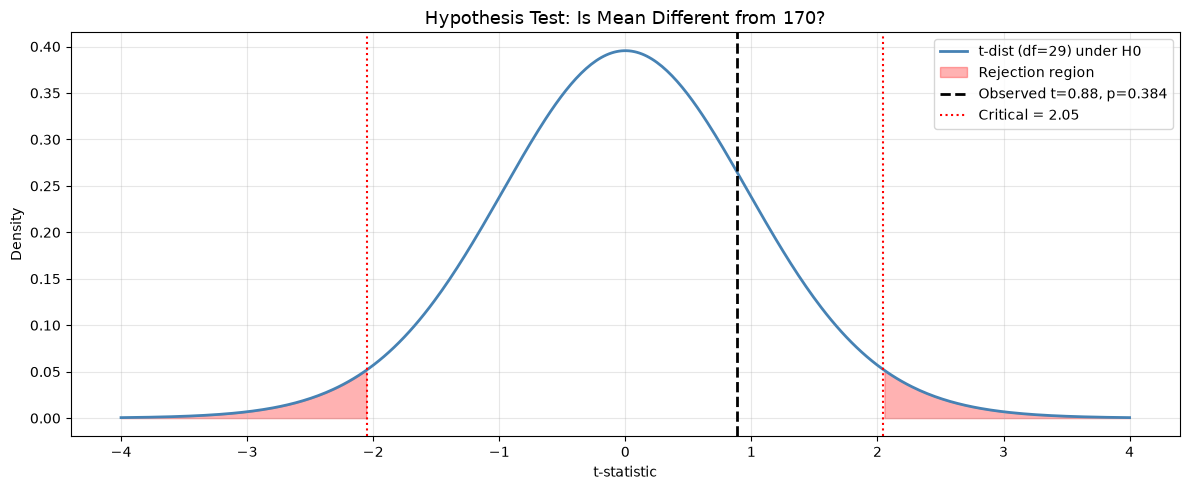

In [4]:
# Visualize t-distribution, rejection regions and observed t
df_deg = n - 1

# Range for t-distribution curve
x = np.linspace(-4, 4, 400)
y = stats.t.pdf(x, df_deg)

# Critical value for two-sided alpha = 0.05
t_crit = stats.t.ppf(1 - alpha/2, df_deg)

plt.figure(figsize=(12, 5))

# Plot t-distribution under H0
plt.plot(x, y, color="steelblue", linewidth=2, label=f"t-dist (df={df_deg}) under H0")

# Shade rejection regions in red
x_rej_left = x[x <= -t_crit]
x_rej_right = x[x >= t_crit]
plt.fill_between(x_rej_left, stats.t.pdf(x_rej_left, df_deg), color="red", alpha=0.3, label="Rejection region")
plt.fill_between(x_rej_right, stats.t.pdf(x_rej_right, df_deg), color="red", alpha=0.3)

# Mark observed t-statistic
plt.axvline(t_obs, color="black", linestyle="--", linewidth=2, label=f"Observed t={t_obs:.2f}, p={p_value:.3f}")
plt.axvline(t_crit, color="red", linestyle=":", label=f"Critical = {t_crit:.2f}")
plt.axvline(-t_crit, color="red", linestyle=":")

plt.title("Hypothesis Test: Is Mean Different from 170?", fontsize=13)
plt.xlabel("t-statistic")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Experiment - how do sample size and distance change p-value?
# Same mean difference but bigger sample
big_sample = np.random.normal(loc=172, scale=6, size=200)
t1, p1 = stats.ttest_1samp(big_sample, popmean=170)
print(f"n=30: p={p_value:.4f} | n=200 same effect: p={p1:.5f}")

# Same sample size but H0 closer to reality
t2, p2 = stats.ttest_1samp(df["height"], popmean=172)
print(f"H0=170: p={p_value:.4f} | H0=172: p={p2:.4f}")

# Question: Why does bigger n give smaller p for the same 2cm difference?
# Question: What happens if you set alpha=0.01 instead of 0.05? Does the decision change?

n=30: p=0.3842 | n=200 same effect: p=0.00000
H0=170: p=0.3842 | H0=172: p=0.2616
